# Comparación: CNN base, VGG16 y EfficientNet-B0

**Pregunta que responde:** ¿por qué la app usa **YOLO + EfficientNet-B0**?

Compara las tres redes que clasifican los recortes de huevos, con YOLO de 3 clases como línea base. Usa los mismos datos para todas y los pesos ya entrenados.


**Reglas.** Las redes se eligen con `valid` y el costo. Las fotos externas **confirman**, pero no se usan para elegir: si se usaran, dejarían de ser una prueba independiente.

**Cómo correrlo.** Con `sbatch dl/scripts/run_comparison.sh` (GPU, unos 10 minutos). Necesita los pesos de `dl/outputs/cnn_final/`, `dl/outputs/transfer_vgg16/`, `dl/outputs/transfer_efficientnet_b0/` y `dl/outputs/yolo/`.

In [1]:
import json
import time
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import torch
import torch.nn as nn
import torch.nn.functional as F
from matplotlib.patches import Rectangle
from PIL import Image, ImageEnhance, ImageFilter, ImageOps
from scipy.stats import binomtest
from sklearn.metrics import accuracy_score, confusion_matrix, f1_score
from torchvision import models as tv_models
from torchvision import transforms as T
from ultralytics import YOLO

## 0. Parámetros, modelos y datos

In [2]:
ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / 'CLAUDE.md').is_file())
CROPS_CSV = ROOT / 'data/crops/crops.csv'
EXTERNAL_SETS = {'completas': ROOT / 'data/external',            
                 'recortadas al ocular': ROOT / 'data/external_fov'}   
DETECTOR_1 = ROOT / 'dl/outputs/yolo/yolo_1class_aug/weights/best.pt'   
DETECTOR_3 = ROOT / 'dl/outputs/yolo/yolo_3class_aug/weights/best.pt'   
RUNS = {'CNN base': ROOT / 'dl/outputs/cnn_final',
        'VGG16': ROOT / 'dl/outputs/transfer_vgg16',
        'EfficientNet-B0': ROOT / 'dl/outputs/transfer_efficientnet_b0'}
CHOSEN = 'EfficientNet-B0'     
SEEDS = [42, 43, 44]            
CLASSES = ['ascaris', 'hookworm', 'trichuris']
IMG_SIZE = 224
MEAN, STD = (0.485, 0.456, 0.406), (0.229, 0.224, 0.225)
MARGIN = 0.15                   
CONF_THRESHOLD = 0.25           
REVIEW_BELOW = 0.65             
CPU_THREADS = 8                
FINAL_TEST = True   # run once (2026-11-11), with EfficientNet-B0 already chosen             
COLORS = {'CNN base': '#eb6834', 'VGG16': '#2a78d6', 'EfficientNet-B0': '#2f9e44', 'YOLO 3 clases': '#7a5195'}

DEVICE = 'cuda' if torch.cuda.is_available() else 'mps' if torch.backends.mps.is_available() else 'cpu'
torch.manual_seed(0)
np.random.seed(0)
print('device:', torch.cuda.get_device_name(0) if DEVICE == 'cuda' else DEVICE)
for p in [CROPS_CSV, DETECTOR_1, DETECTOR_3, *EXTERNAL_SETS.values()]:
    assert p.exists(), f'missing {p}'

device: NVIDIA H100 NVL


In [3]:
class Block(nn.Module):
    def __init__(self, cin, cout, residual):
        super().__init__()
        self.conv1 = nn.Sequential(nn.Conv2d(cin, cout, 3, padding=1, bias=False), nn.BatchNorm2d(cout), nn.ReLU(inplace=True))
        self.conv2 = nn.Sequential(nn.Conv2d(cout, cout, 3, padding=1, bias=False), nn.BatchNorm2d(cout))
        self.skip = nn.Sequential(nn.Conv2d(cin, cout, 1, bias=False), nn.BatchNorm2d(cout)) if residual else None
        self.pool = nn.MaxPool2d(2)

    def forward(self, x):
        out = self.conv2(self.conv1(x))
        if self.skip is not None:
            out = out + self.skip(x)
        return self.pool(F.relu(out))


class CNN(nn.Module):
    def __init__(self, blocks, width, residual, dropout, n_classes=3):
        super().__init__()
        chans = [3] + [width * 2 ** i for i in range(blocks)]
        self.features = nn.Sequential(*[Block(chans[i], chans[i + 1], residual) for i in range(blocks)])
        self.head = nn.Sequential(nn.AdaptiveAvgPool2d(1), nn.Flatten(), nn.Dropout(dropout), nn.Linear(chans[-1], n_classes))

    def forward(self, x):
        return self.head(self.features(x))


class TransferNet(nn.Module):
    def __init__(self, features, channels, dropout, n_classes=3):
        super().__init__()
        self.features = features
        self.head = nn.Sequential(nn.AdaptiveAvgPool2d(1), nn.Flatten(), nn.Dropout(dropout), nn.Linear(channels, n_classes))

    def forward(self, x):
        return self.head(self.features(x))


def build(name, cfg):
    if name == 'CNN base':
        return CNN(cfg['blocks'], cfg['width'], cfg['residual'], cfg['dropout'])
    if name == 'VGG16':
        features = tv_models.vgg16(weights=None).features
        for layer in features:
            if isinstance(layer, nn.ReLU):
                layer.inplace = False      # Grad-CAM reads these activations
        return TransferNet(features, 512, cfg['dropout'])
    return TransferNet(tv_models.efficientnet_b0(weights=None).features, 1280, cfg['dropout'])


def load(name, seed, device=DEVICE):
    run = RUNS[name] / f'seed{seed}'
    model = build(name, json.loads((run / 'config.json').read_text()))
    model.load_state_dict(torch.load(run / 'best.pt', map_location='cpu'))
    return model.to(device).eval()


models = {name: [load(name, s) for s in SEEDS] for name in RUNS}
dones = {name: [json.loads((RUNS[name] / f'seed{s}' / 'done.json').read_text()) for s in SEEDS] for name in RUNS}
histories = {name: [pd.read_csv(RUNS[name] / f'seed{s}' / 'history.csv') for s in SEEDS] for name in RUNS}
print({name: len(ms) for name, ms in models.items()}, 'models loaded')

{'CNN base': 3, 'VGG16': 3, 'EfficientNet-B0': 3} models loaded


In [4]:
def pad_to_square(img):
    side = max(img.size)
    fill = tuple(int(c) for c in np.asarray(img).reshape(-1, 3).mean(axis=0))
    return ImageOps.pad(img, (side, side), color=fill, centering=(0.5, 0.5))


TF = T.Compose([T.Resize((IMG_SIZE, IMG_SIZE), interpolation=T.InterpolationMode.BICUBIC), T.ToTensor(), T.Normalize(MEAN, STD)])


@torch.no_grad()
def seed_probs(model_list, images, batch=64):
    out = []
    for m in model_list:
        parts = [F.softmax(m(torch.stack([TF(im) for im in images[i:i + batch]]).to(DEVICE)), 1).cpu()
                 for i in range(0, len(images), batch)]
        out.append(torch.cat(parts).numpy())
    return np.stack(out)


crops = pd.read_csv(CROPS_CSV)
valid = crops[crops.split == 'valid'].reset_index(drop=True)
valid_imgs = [pad_to_square(Image.open(ROOT / p).convert('RGB')) for p in valid.crop_path]
y = np.array([CLASSES.index(label) for label in valid.label])

P = {name: seed_probs(ms, valid_imgs) for name, ms in models.items()}   # per seed
ENS = {name: p.mean(0) for name, p in P.items()}                       # 3-seed average, as the app
PRED = {name: p.argmax(1) for name, p in ENS.items()}
print(f'valid: {len(y)} crops |', valid.label.value_counts().to_dict())

valid: 413 crops | {'hookworm': 140, 'trichuris': 137, 'ascaris': 136}


## 1. Resumen: arquitectura, tamaño y F1

El F1 por semilla es la media ± desviación de las 3 redes entrenadas con semillas distintas. El F1 del conjunto es el de promediar las 3 semillas, que es lo que hace la app. Los parámetros "entrenables" son los que se ajustan: toda la red en la CNN, y solo los últimos bloques en las preentrenadas.

In [5]:
ARCH_INFO = {
    'CNN base': ('5 bloques conv 3×3 (diseño propio), desde cero', 'Simonyan y Zisserman (2015), estilo VGG'),
    'VGG16': ('VGG16 de ImageNet sin capas densas + cabeza de la CNN', 'Simonyan y Zisserman (2015)'),
    'EfficientNet-B0': ('EfficientNet-B0 de ImageNet + cabeza de la CNN', 'Tan y Le (2019)'),
}
rows = {}
for name in RUNS:
    f1_seeds = [f1_score(y, P[name][k].argmax(1), average='macro') for k in range(len(SEEDS))]
    n_params = dones[name][0]['n_params']
    trainable = dones[name][0].get('trainable_phase2', n_params)
    rows[name] = {
        'arquitectura': ARCH_INFO[name][0], 'referencia': ARCH_INFO[name][1],
        'parámetros (M)': round(n_params / 1e6, 2), 'entrenables (M)': round(trainable / 1e6, 2),
        'pesos por semilla (MB)': round((RUNS[name] / 'seed42' / 'best.pt').stat().st_size / 1e6, 1),
        'F1 valid por semilla': f'{np.mean(f1_seeds):.4f} ± {np.std(f1_seeds, ddof=1):.4f}',
        'F1 valid conjunto 3 semillas': round(f1_score(y, PRED[name], average='macro'), 4),
        'errores (de 413)': int((PRED[name] != y).sum()),
        'mejor época (media)': round(np.mean([d['best_epoch'] for d in dones[name]]), 1),
        'min de entrenamiento (media, H100)': round(np.mean([d['minutes'] for d in dones[name]]), 2),
    }
summary = pd.DataFrame(rows).T
summary

,arquitectura,referencia,parámetros (M),entrenables (M),pesos por semilla (MB),F1 valid por semilla,F1 valid conjunto 3 semillas,errores (de 413),mejor época (media),"min de entrenamiento (media, H100)"
CNN base,"5 bloques conv 3×3 (diseño propio), desde cero","Simonyan y Zisserman (2015), estilo VGG",4.72,4.72,18.9,0.9919 ± 0.0014,0.9927,3,72.3,2.96
VGG16,VGG16 de ImageNet sin capas densas + cabeza de...,Simonyan y Zisserman (2015),14.72,12.98,58.9,0.9959 ± 0.0028,0.9976,1,13.3,0.8
EfficientNet-B0,EfficientNet-B0 de ImageNet + cabeza de la CNN,Tan y Le (2019),4.01,3.16,16.3,0.9935 ± 0.0014,0.9951,2,20.0,0.98


In [6]:
det_rows = {}
for label, weights in [('YOLO 1 clase (detector del sistema)', DETECTOR_1), ('YOLO 3 clases (línea base)', DETECTOR_3)]:
    res = pd.read_csv(weights.parent.parent / 'results.csv')
    res.columns = res.columns.str.strip()
    best = res.loc[res['metrics/mAP50-95(B)'].idxmax()]
    det_rows[label] = {'época': int(best['epoch']), 'precisión': best['metrics/precision(B)'], 'recall': best['metrics/recall(B)'],
                       'mAP50': best['metrics/mAP50(B)'], 'mAP50-95': best['metrics/mAP50-95(B)']}
pd.DataFrame(det_rows).T.round(3)

,época,precisión,recall,mAP50,mAP50-95
YOLO 1 clase (detector del sistema),95.0,0.997,0.990,0.995,0.923
YOLO 3 clases (línea base),99.0,0.987,0.994,0.995,0.917


**Comparación de los dos detectores en `valid` (corridas con aumentos, mejor época por mAP50-95).** El YOLO de 1 clase (detector del sistema) y el de 3 clases (línea base) quedan prácticamente empatados: mAP50 de 0,995 en ambos (saturado, no discrimina) y mAP50-95 de 0,923 (época 95) frente a 0,917 (época 99), una diferencia de 0,006 con una sola corrida por modelo. La precisión es mayor en el de 1 clase (0,997 frente a 0,987) y el recall algo mayor en el de 3 clases (0,994 frente a 0,990); parte de la menor precisión del de 3 clases se debe a que una caja con la especie equivocada cuenta como falsa alarma. Pedirle también la especie no empeora la localización en `valid`. Esta tabla compara solo la detección: la elección entre el sistema YOLO 1 clase + clasificador y el YOLO de 3 clases debe decidirse con el acierto de especie y con las fotos externas. Como `valid` se usa tanto para elegir la mejor época como para reportar, las cifras pueden ser algo optimistas.


## 2. Curvas de aprendizaje superpuestas

Una línea por semilla. La zona gris son las 5 épocas de la fase 1 de las redes preentrenadas, con la red congelada y solo la cabeza entrenándose. Si la pérdida de `valid` sube mientras la de `train` baja, hay sobreajuste.

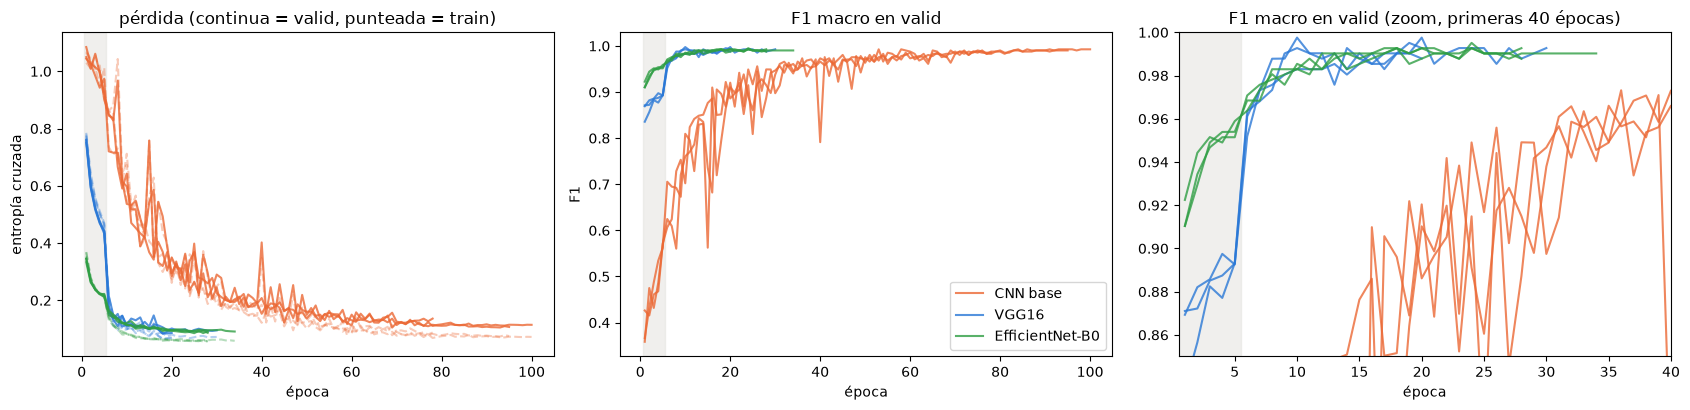

In [7]:
fig, axes = plt.subplots(1, 3, figsize=(17, 4.2))
for name, hs in histories.items():
    for k, h in enumerate(hs):
        lab = name if k == 0 else None
        axes[0].plot(h.epoch, h.val_loss, color=COLORS[name], alpha=0.8, label=lab)
        axes[0].plot(h.epoch, h.train_loss, color=COLORS[name], alpha=0.35, ls='--')
        axes[1].plot(h.epoch, h.val_f1, color=COLORS[name], alpha=0.8, label=lab)
        axes[2].plot(h.epoch, h.val_f1, color=COLORS[name], alpha=0.8, label=lab)
for ax in axes:
    ax.axvspan(0.5, 5.5, color='#e6e5e1', alpha=0.6, zorder=0)
    ax.set_xlabel('época')
axes[0].set(title='pérdida (continua = valid, punteada = train)', ylabel='entropía cruzada')
axes[1].set(title='F1 macro en valid', ylabel='F1')
axes[2].set(title='F1 macro en valid (zoom, primeras 40 épocas)', xlim=(0.5, 40), ylim=(0.85, 1.0))
axes[1].legend()
plt.tight_layout()
plt.show()

**Curvas de entrenamiento: CNN base, VGG16 y EfficientNet-B0 (3 semillas cada una).** Los modelos de transferencia parten de un punto mucho mejor: en la época 1, la pérdida en `valid` es ~0,76 (VGG16) y ~0,34 (EfficientNet-B0) frente a ~1,08 de la CNN base, y el F1 es de 0,84 a 0,92 frente a 0,36 a 0,43. La banda gris marca la fase 1 (épocas 1 a 5), en la que solo se entrena la cabeza con la red congelada; al descongelar los últimos bloques (fase 2) la pérdida cae de golpe y el F1 supera 0,98 hacia la época 10. La CNN base necesita de 45 a 59 épocas para llegar a 0,98 y sus curvas son más ruidosas. La receta de transferencia tiene como máximo 35 épocas (5 + 30) y una parada temprana de paciencia 10, por lo que VGG16 se detuvo en 30, 20 y 20 épocas y EfficientNet-B0 en 28, 34 y 28; la CNN base corrió 78, 95 y 100. El tercer panel es un zoom de las primeras 40 épocas. Al final los tres modelos quedan en un F1 de ~0,99 en `valid` (VGG16 0,9927 a 0,9976, EfficientNet-B0 0,9927 a 0,9951, CNN base 0,9902 a 0,9927), diferencias de 1 a 3 errores sobre 413, así que `valid` no permite separarlos. Las épocas no son comparables entre familias, porque cada una actualiza un número distinto de pesos y usa paciencias distintas.


## 3. ¿Las diferencias en `valid` son reales?

Las tres redes se miden en los mismos 413 recortes, así que se pueden comparar **pareadas**:

- **McNemar (exacto):** de los recortes en que las dos redes no coinciden en acertar, ¿gana una mucho más que la otra? Si p > 0,05, no hay evidencia de que una sea mejor.
- **Bootstrap pareado** de la diferencia de F1 macro (2.000 remuestreos): si el intervalo incluye el 0, la diferencia no es concluyente.

Se usa el conjunto de 3 semillas de cada red, como en la app.

In [8]:
rng = np.random.default_rng(42)
boot_idx = rng.integers(0, len(y), size=(2000, len(y)))
names = list(RUNS)
pair_rows = []
for i, a in enumerate(names):
    for b in names[i + 1:]:
        ra, rb = PRED[a] == y, PRED[b] == y
        only_a, only_b = int((ra & ~rb).sum()), int((~ra & rb).sum())
        p = binomtest(min(only_a, only_b), only_a + only_b, 0.5).pvalue if only_a + only_b else 1.0
        diffs = [f1_score(y[ix], PRED[a][ix], average='macro') - f1_score(y[ix], PRED[b][ix], average='macro') for ix in boot_idx]
        lo, hi = np.percentile(diffs, [2.5, 97.5])
        pair_rows.append({'par': f'{a} vs {b}', f'solo acierta A': only_a, 'solo acierta B': only_b,
                          'McNemar p': round(p, 3), 'ΔF1 (A − B)': round(f1_score(y, PRED[a], average='macro') - f1_score(y, PRED[b], average='macro'), 4),
                          'IC 95 % ΔF1': f'[{lo:+.4f}, {hi:+.4f}]'})
pairs = pd.DataFrame(pair_rows).set_index('par')
pairs

,solo acierta A,solo acierta B,McNemar p,ΔF1 (A − B),IC 95 % ΔF1
par,,,,,
CNN base vs VGG16,1,3,0.625,-0.0049,"[-0.0147, +0.0046]"
CNN base vs EfficientNet-B0,2,3,1.000,-0.0024,"[-0.0126, +0.0076]"
VGG16 vs EfficientNet-B0,2,1,1.000,0.0024,"[-0.0050, +0.0115]"


In [9]:
wrong_any = np.where(np.any([PRED[n] != y for n in names], axis=0))[0]
errs = valid.loc[wrong_any, ['crop_path', 'label']].copy()
for n in names:
    errs[n] = [CLASSES[PRED[n][i]] + ('' if PRED[n][i] == y[i] else ' ✗') for i in wrong_any]
print(f'{len(wrong_any)} crops are wrong for at least one network; '
      f'{int(np.all([PRED[n][wrong_any] != y[wrong_any] for n in names], axis=0).sum())} are wrong for all three')
errs['crop_path'] = errs.crop_path.str.replace('data/crops/valid/', '', regex=False)
errs

6 crops are wrong for at least one network; 0 are wrong for all three


,crop_path,label,CNN base,VGG16,EfficientNet-B0
100,ascaris/Ascaris-lumbricoides_0749_jpg.rf.bbc7f...,ascaris,hookworm ✗,ascaris,ascaris
120,ascaris/Ascaris-lumbricoides_0871_jpg.rf.845fe...,ascaris,trichuris ✗,ascaris,ascaris
304,trichuris/Trichuris-trichiura_0286_jpg.rf.6665...,trichuris,ascaris ✗,trichuris,trichuris
390,trichuris/Trichuris-trichiura_0851_jpg.rf.2303...,trichuris,trichuris,trichuris,ascaris ✗
394,trichuris/Trichuris-trichiura_0875_jpg.rf.e0e6...,trichuris,trichuris,ascaris ✗,trichuris
412,trichuris/Trichuris-trichiura_1000_jpg.rf.21fb...,trichuris,trichuris,trichuris,ascaris ✗


## 4. Confianza: el umbral de 65 % de la app

La app marca para revisión de un profesional todo huevo con confianza (probabilidad máxima del softmax, promediando 3 semillas) menor a 65 %. Para que eso sirva, los errores deben tener confianza baja. Aquí se mide, en `valid`, para cada red:

- **Cobertura con umbral 0,65:** qué fracción de huevos se acepta sin revisión.
- **Exactitud de lo aceptado:** de esos, cuántos acierta.
- **ECE** (*expected calibration error*, 10 intervalos): la distancia media entre la confianza y el acierto real. Menor es mejor: una red bien calibrada que dice 80 % acierta cerca del 80 % de las veces.

Con apenas 2 a 4 errores por red, estas cifras son indicativas.

,confianza media (aciertos),confianza media (errores),cobertura con ≥ 0.65,exactitud de lo aceptado,errores que se escapan sin revisión,ECE
CNN base,0.9028,0.5800,0.9709,1.0000,0.0,0.0923
VGG16,0.9059,0.6575,0.9685,0.9975,1.0,0.0923
EfficientNet-B0,0.9189,0.6134,0.9855,0.9975,1.0,0.0783


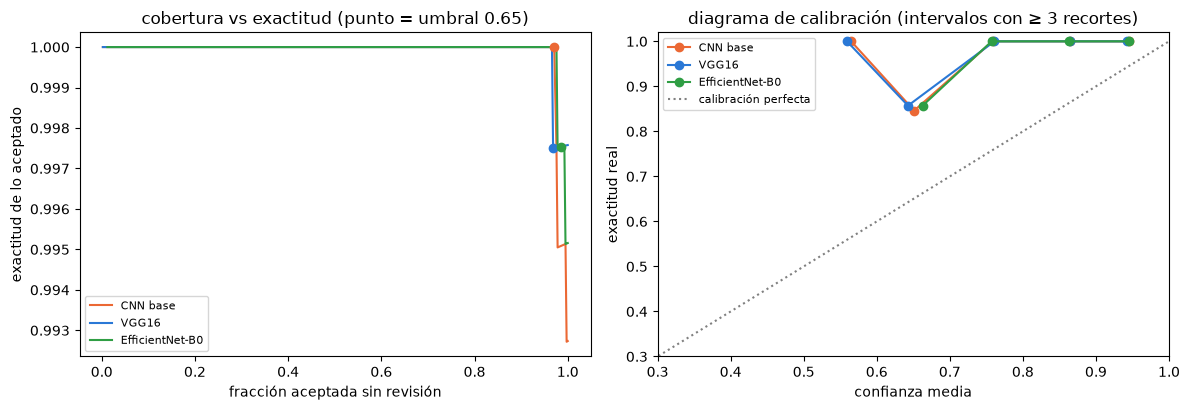

In [10]:
def ece(conf, correct, bins=10):
    edges = np.linspace(0, 1, bins + 1)
    total = 0.0
    for lo, hi in zip(edges[:-1], edges[1:]):
        m = (conf > lo) & (conf <= hi)
        if m.any():
            total += m.mean() * abs(correct[m].mean() - conf[m].mean())
    return total


conf_rows = {}
for n in names:
    conf, correct = ENS[n].max(1), PRED[n] == y
    keep = conf >= REVIEW_BELOW
    conf_rows[n] = {'confianza media (aciertos)': conf[correct].mean(),
                    'confianza media (errores)': conf[~correct].mean() if (~correct).any() else np.nan,
                    f'cobertura con ≥ {REVIEW_BELOW}': keep.mean(),
                    'exactitud de lo aceptado': correct[keep].mean(),
                    'errores que se escapan sin revisión': int((~correct & keep).sum()),
                    'ECE': ece(conf, correct)}
confidence = pd.DataFrame(conf_rows).T.round(4)
display(confidence)

thresholds = np.linspace(0.34, 0.99, 66)
fig, axes = plt.subplots(1, 2, figsize=(12, 4.2))
for n in names:
    conf, correct = ENS[n].max(1), PRED[n] == y
    cov = [np.mean(conf >= t) for t in thresholds]
    acc = [correct[conf >= t].mean() if (conf >= t).any() else np.nan for t in thresholds]
    axes[0].plot(cov, acc, color=COLORS[n], label=n)
    k = np.argmin(np.abs(thresholds - REVIEW_BELOW))
    axes[0].scatter([cov[k]], [acc[k]], color=COLORS[n], zorder=3)
    edges = np.linspace(0, 1, 11)
    mids, accs = [], []
    for lo, hi in zip(edges[:-1], edges[1:]):
        m = (conf > lo) & (conf <= hi)
        if m.sum() >= 3:
            mids.append(conf[m].mean()); accs.append(correct[m].mean())
    axes[1].plot(mids, accs, marker='o', color=COLORS[n], label=n)
axes[0].set(title=f'cobertura vs exactitud (punto = umbral {REVIEW_BELOW})', xlabel='fracción aceptada sin revisión', ylabel='exactitud de lo aceptado')
axes[1].plot([0, 1], [0, 1], color='gray', ls=':', label='calibración perfecta')
axes[1].set(title='diagrama de calibración (intervalos con ≥ 3 recortes)', xlabel='confianza media', ylabel='exactitud real', xlim=(0.3, 1.0), ylim=(0.3, 1.02))
for ax in axes:
    ax.legend(fontsize=8)
plt.tight_layout()
plt.show()

**Cobertura frente a exactitud y calibración en `valid` (413 recortes).** En la curva de cobertura, el eje vertical está muy ampliado (0,993 a 1,000): toda la variación corresponde a 3 errores en 413 recortes (cada error equivale a ~0,0024). Con un umbral de confianza de 0,65 se aceptan sin revisión ~97 a 98 % de los recortes, sin errores en la CNN base y con uno en VGG16 y EfficientNet-B0; los errores se concentran en el último ~3 % de los recortes, los de menor confianza, por lo que la confianza ordena bien los casos dudosos. En el diagrama de calibración, todos los puntos quedan por encima de la diagonal: los modelos son subconfiados (aciertan más de lo que su confianza indica), algo esperable con *label smoothing*. El único intervalo con aciertos por debajo de 1 está en una confianza media de ~0,65 (~0,85 de acierto), donde hay pocos recortes y uno o dos errores mueven mucho el valor. Los tres modelos son prácticamente indistinguibles. La confianza sirve para priorizar qué revisar, pero no debe leerse como una probabilidad literal. Estos resultados son sobre `valid`, que es de la misma fuente que `train`; la calibración en fotos externas debe evaluarse aparte.


## 5. Costo en la laptop de campo

Todas las latencias se miden **en esta misma corrida**, en CPU, con el mismo número de hilos (`CPU_THREADS` = 8, el número que fija Ultralytics al predecir). Antes cada notebook medía en una corrida distinta, y esas cifras no eran comparables entre sí. Las medidas son:

- **Por recorte:** una red, un recorte a la vez.
- **Por recorte, 3 semillas:** lo que hace la app.
- **Por foto (sistema completo):** YOLO sobre la foto completa más la clasificación de sus recortes con las 3 semillas, promediado sobre 10 fotos externas.

Son cifras de este nodo, no de la laptop final: sirven para comparar las redes entre sí.

In [11]:
cpu_models = {n: [load(n, s, 'cpu') for s in SEEDS] for n in names}
detector_cpu = YOLO(str(DETECTOR_1))
torch.set_num_threads(CPU_THREADS)   
sample = torch.randn(1, 3, IMG_SIZE, IMG_SIZE)


@torch.no_grad()
def latency_ms(model_list, runs=20):
    for _ in range(3):
        for m in model_list:
            m(sample)
    start = time.perf_counter()
    for _ in range(runs):
        for m in model_list:
            m(sample)
    return (time.perf_counter() - start) / runs * 1000


def expand(box, width, height):
    x1, y1, x2, y2 = box
    dw, dh = (x2 - x1) * MARGIN, (y2 - y1) * MARGIN
    return (max(0, int(round(x1 - dw))), max(0, int(round(y1 - dh))), min(width, int(round(x2 + dw))), min(height, int(round(y2 + dh))))


ext_csv = pd.read_csv(EXTERNAL_SETS['completas'] / 'external.csv')
photo_paths = [EXTERNAL_SETS['completas'] / f for f in ext_csv[ext_csv.uso == 'prueba'].image.iloc[5:15]]
photos = [ImageOps.exif_transpose(Image.open(p)).convert('RGB') for p in photo_paths]
detector_cpu.predict(source=photos[0], imgsz=640, conf=CONF_THRESHOLD, device='cpu', verbose=False)   # warm-up

cost_rows = {}
for n in names:
    per_photo = []
    for img in photos:
        start = time.perf_counter()
        r = detector_cpu.predict(source=img, imgsz=640, conf=CONF_THRESHOLD, device='cpu', verbose=False)[0]
        cs = [pad_to_square(img.crop(expand(b, *img.size))) for b in r.boxes.xyxy.tolist()]
        if cs:
            with torch.no_grad():
                x = torch.stack([TF(c) for c in cs])
                torch.stack([F.softmax(m(x), 1) for m in cpu_models[n]]).mean(0)
        per_photo.append(time.perf_counter() - start)
    size = sum((RUNS[n] / f'seed{s}' / 'best.pt').stat().st_size for s in SEEDS) / 1e6
    cost_rows[n] = {'ms por recorte (1 semilla)': latency_ms(cpu_models[n][:1]),
                    'ms por recorte (3 semillas)': latency_ms(cpu_models[n]),
                    's por foto, YOLO + 3 semillas': np.mean(per_photo),
                    'pesos de las 3 semillas (MB)': size}
cost = pd.DataFrame(cost_rows).T.round(2)
print(f'CPU threads: {torch.get_num_threads()} | YOLO 1 clase weights: {DETECTOR_1.stat().st_size / 1e6:.1f} MB')
cost

CPU threads: 8 | YOLO 1 clase weights: 5.5 MB


,ms por recorte (1 semilla),ms por recorte (3 semillas),"s por foto, YOLO + 3 semillas",pesos de las 3 semillas (MB)
CNN base,11.72,35.34,0.10,56.69
VGG16,37.36,112.72,0.18,176.62
EfficientNet-B0,11.05,33.72,0.10,48.97


## 6. Robustez a brillo y desenfoque

Las perturbaciones se aplican a los recortes de `valid`, sin volver a entrenar. Se mide el F1 macro del conjunto de 3 semillas. Brillo 1,0 y desenfoque 0 son las imágenes originales. La zona gris es el rango de brillo que cubren los aumentos de entrenamiento (×0,7 a ×1,3).

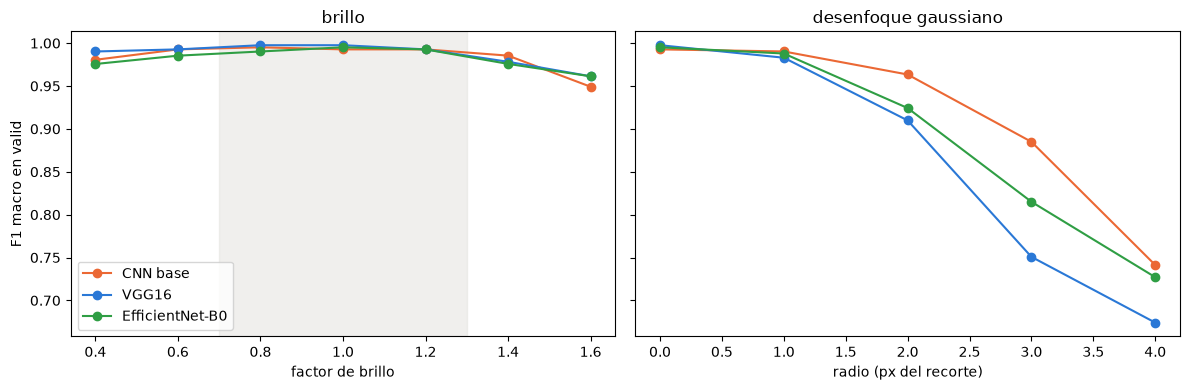

brillo,0.4,0.6,0.8,1.0,1.2,1.4,1.6
CNN base,0.9805,0.9927,0.9951,0.9927,0.9927,0.9854,0.9491
VGG16,0.9902,0.9927,0.9976,0.9976,0.9927,0.9782,0.9613
EfficientNet-B0,0.9757,0.9853,0.9902,0.9951,0.9927,0.9758,0.9613


radio de desenfoque,0,1,2,3,4
CNN base,0.9927,0.9903,0.9634,0.8849,0.7413
VGG16,0.9976,0.9830,0.9099,0.7508,0.6741
EfficientNet-B0,0.9951,0.9879,0.9243,0.8150,0.7271


In [12]:
BRIGHTNESS = [0.4, 0.6, 0.8, 1.0, 1.2, 1.4, 1.6]
BLUR_RADIUS = [0, 1, 2, 3, 4]
robust = {}
for n in names:
    robust[(n, 'brillo')] = [f1_score(y, seed_probs(models[n], [ImageEnhance.Brightness(im).enhance(f) for im in valid_imgs]).mean(0).argmax(1), average='macro') for f in BRIGHTNESS]
    robust[(n, 'desenfoque')] = [f1_score(y, seed_probs(models[n], [im.filter(ImageFilter.GaussianBlur(r)) if r else im for im in valid_imgs]).mean(0).argmax(1), average='macro') for r in BLUR_RADIUS]

fig, axes = plt.subplots(1, 2, figsize=(12, 4), sharey=True)
for n in names:
    axes[0].plot(BRIGHTNESS, robust[(n, 'brillo')], marker='o', color=COLORS[n], label=n)
    axes[1].plot(BLUR_RADIUS, robust[(n, 'desenfoque')], marker='o', color=COLORS[n], label=n)
axes[0].axvspan(0.7, 1.3, color='#e6e5e1', alpha=0.6, zorder=0)
axes[0].set(title='brillo', xlabel='factor de brillo', ylabel='F1 macro en valid')
axes[1].set(title='desenfoque gaussiano', xlabel='radio (px del recorte)')
axes[0].legend()
plt.tight_layout()
plt.show()
display(pd.DataFrame({n: robust[(n, 'brillo')] for n in names}, index=BRIGHTNESS).rename_axis('brillo').T.round(4))
pd.DataFrame({n: robust[(n, 'desenfoque')] for n in names}, index=BLUR_RADIUS).rename_axis('radio de desenfoque').T.round(4)

## 7. ¿Qué mira cada red? Grad-CAM

Se usan los mismos recortes para las tres redes (semilla 42): el acierto más seguro de cada especie según EfficientNet-B0 y los recortes que falla alguna red. El mapa (rojo = más importante) sale de la última activación convolucional de cada red: la CNN tiene 7 × 7, VGG16 14 × 14 y EfficientNet-B0 7 × 7, estiradas a 224 × 224. Una red confiable debería mirar el huevo (cáscara, tapones, contenido) y no el fondo. El PLAN pide que un parasitólogo revise estos mapas.

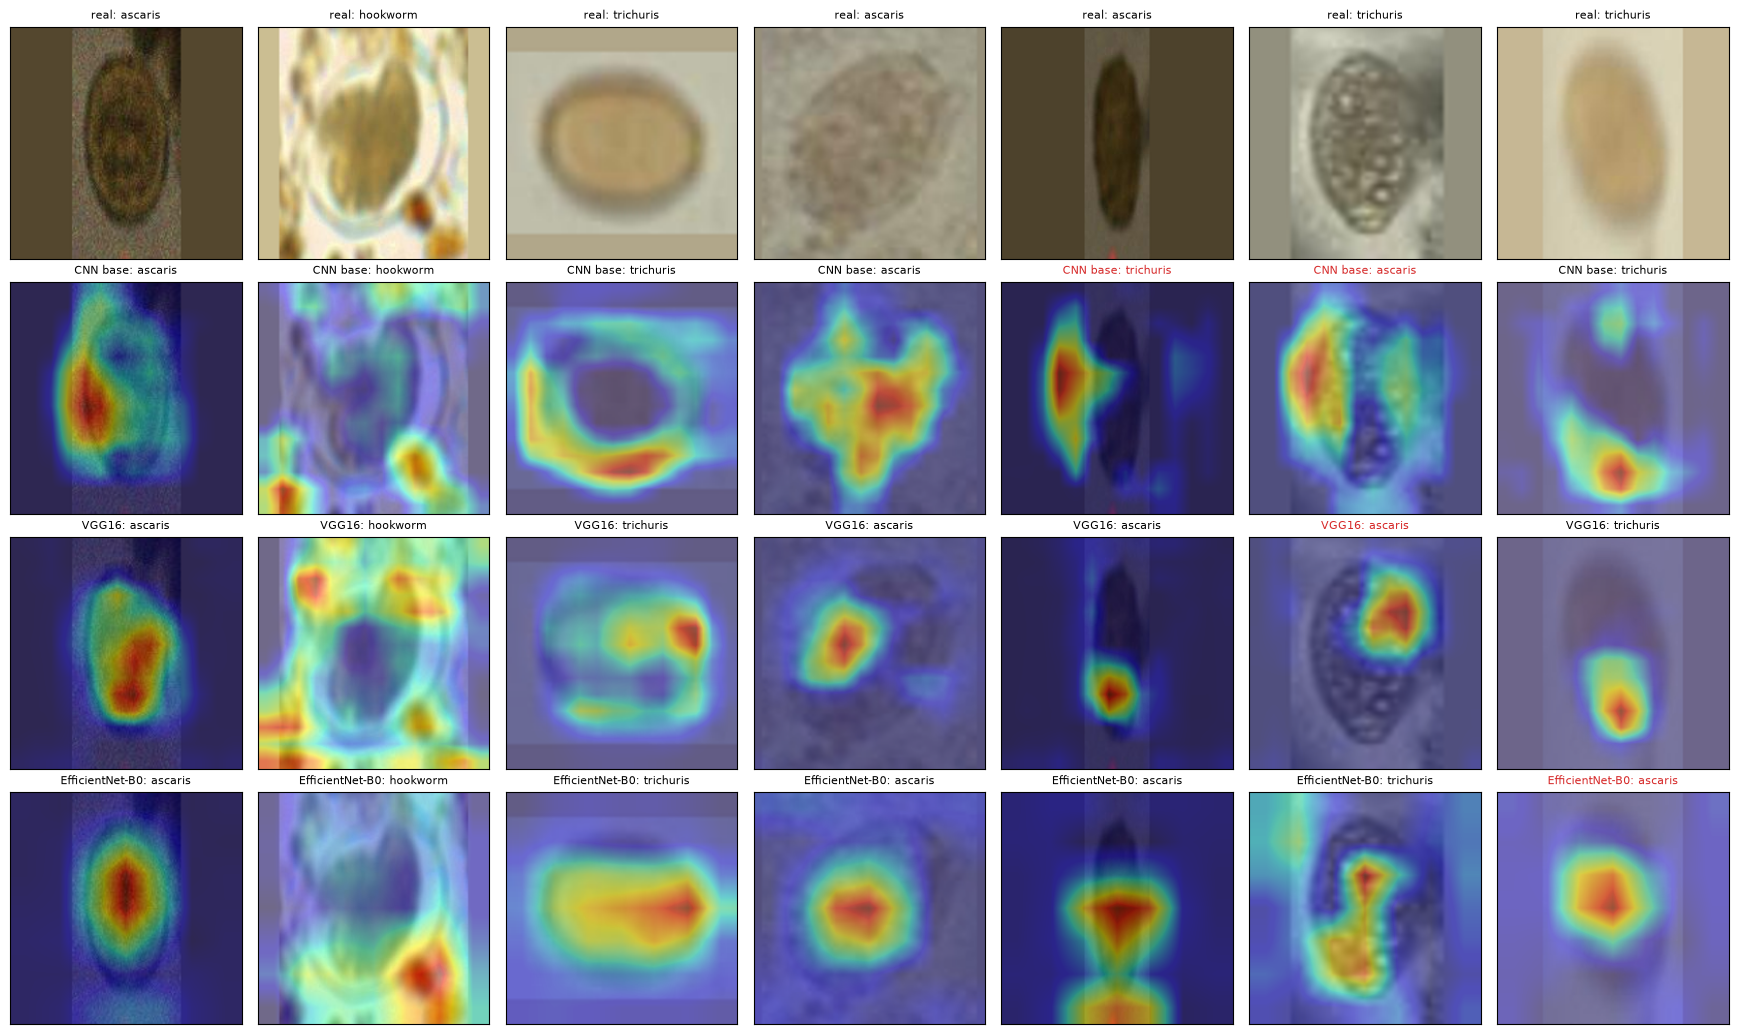

In [13]:
CAM_LAYER = {'CNN base': lambda m: m.features[-1].conv2,
             'VGG16': lambda m: m.features[29],
             'EfficientNet-B0': lambda m: m.features[-1]}


def grad_cam(model, layer, x):
    store = {}

    def keep(module, inputs, output):
        store['a'] = output
        output.register_hook(lambda grad: store.update(g=grad))

    handle = layer.register_forward_hook(keep)
    try:
        out = model(x)
        target = int(out.argmax(1).item())
        model.zero_grad()
        out[0, target].backward()
    finally:
        handle.remove()
    cam = F.relu((store['g'].mean(dim=(2, 3), keepdim=True) * store['a']).sum(1, keepdim=True))
    cam = F.interpolate(cam, size=x.shape[-2:], mode='bilinear', align_corners=False)[0, 0]
    cam = (cam - cam.min()) / (cam.max() - cam.min() + 1e-8)
    return cam.detach().cpu().numpy(), target


conf_chosen = ENS[CHOSEN].max(1)
examples = [int(np.where((PRED[CHOSEN] == y) & (y == c))[0][np.argmax(conf_chosen[(PRED[CHOSEN] == y) & (y == c)])]) for c in range(3)]
examples += [int(i) for i in wrong_any[:4]]
fig, axes = plt.subplots(1 + len(names), len(examples), figsize=(2.5 * len(examples), 2.6 * (1 + len(names))), squeeze=False)
for col, i in enumerate(examples):
    x = TF(valid_imgs[i]).unsqueeze(0).to(DEVICE)
    axes[0, col].imshow(valid_imgs[i].resize((IMG_SIZE, IMG_SIZE)))
    axes[0, col].set_title(f'real: {CLASSES[y[i]]}', fontsize=8)
    for row, n in enumerate(names, start=1):
        m = models[n][0]
        cam, target = grad_cam(m, CAM_LAYER[n](m), x)
        axes[row, col].imshow(valid_imgs[i].resize((IMG_SIZE, IMG_SIZE)))
        axes[row, col].imshow(cam, cmap='jet', alpha=0.45)
        axes[row, col].set_title(f'{n}: {CLASSES[target]}', fontsize=8, color='black' if target == y[i] else '#d62828')
for ax in axes.ravel():
    ax.set_xticks([]); ax.set_yticks([])
plt.tight_layout()
plt.show()

## 8. Sistema completo en fotos externas

Son fotos de celular por el ocular que la red nunca vio (98 fotos de prueba con 101 huevos, de una sola fuente). Se comparan dos versiones:

- **Completas:** como las recibe la app hoy.
- **Recortadas al ocular:** `data/external_fov/`, con el recorte de `crop_field_of_view.py`.

Las rutas que se evalúan son:

- **YOLO 1 clase + red:** el sistema en dos etapas, con cada una de las tres redes.
- **YOLO 3 clases:** la línea base, que detecta y clasifica a la vez.

Las métricas son las mismas de los otros notebooks:

- `encontrados = min(cajas, huevos reales)`;
- `especie correcta` cuenta las cajas con la especie de la carpeta, hasta el número de encontrados;
- el porcentaje es sobre los encontrados.

**Límites:** no hay cajas dibujadas a mano, el número de huevos por foto se asumió en 1, hay fotos repetidas del mismo huevo y el recorte al ocular se decidió después de ver resultados. Esto **confirma** la elección, no la decide.

In [14]:
detector_1 = YOLO(str(DETECTOR_1))
detector_3 = YOLO(str(DETECTOR_3))
DET_DEVICE = 0 if DEVICE == 'cuda' else 'cpu'


def run_external(folder):
    table = pd.read_csv(folder / 'external.csv')
    table = table[(table.uso == 'prueba') & table.species.notna()].reset_index(drop=True)
    two_stage, one_stage = [], []
    for photo in table.itertuples():
        img = ImageOps.exif_transpose(Image.open(folder / photo.image)).convert('RGB')   # upright, as YOLO sees it
        r = detector_1.predict(source=img, imgsz=640, conf=CONF_THRESHOLD, device=DET_DEVICE, verbose=False)[0]
        boxes = [expand(b, *img.size) for b in r.boxes.xyxy.tolist()]
        boxes = [b for b in boxes if min(b[2] - b[0], b[3] - b[1]) >= 16]
        if boxes:
            cs = [pad_to_square(img.crop(b)) for b in boxes]
            preds = {n: seed_probs(models[n], cs).mean(0) for n in names}
            for k in range(len(boxes)):
                two_stage.append({'image': photo.image, 'species': photo.species,
                                  **{n: CLASSES[int(preds[n][k].argmax())] for n in names},
                                  **{f'conf {n}': float(preds[n][k].max()) for n in names}})
        r3 = detector_3.predict(source=img, imgsz=640, conf=CONF_THRESHOLD, device=DET_DEVICE, verbose=False)[0]
        for c in r3.boxes.cls.tolist():
            one_stage.append({'image': photo.image, 'species': photo.species, 'YOLO 3 clases': detector_3.names[int(c)]})
    return table, pd.DataFrame(two_stage), pd.DataFrame(one_stage)


def summarize(table, boxes, column):
    real = table.set_index('image').n_items.astype(int)
    species_of = table.set_index('image').species
    got = boxes.groupby('image').size().reindex(real.index, fill_value=0) if len(boxes) else real * 0
    found = np.minimum(got, real)
    right = boxes[boxes[column] == boxes.image.map(species_of)].groupby('image').size().reindex(real.index, fill_value=0) if len(boxes) else real * 0
    ok = np.minimum(right, found)
    out = {}
    for sp in CLASSES + ['total']:
        m = (species_of == sp) if sp != 'total' else species_of.notna()
        out[sp] = f'{int(ok[m].sum())}/{int(found[m].sum())}'
    out.update({'huevos reales': int(real.sum()), 'cajas': int(got.sum()), 'encontrados': int(found.sum()),
                'especie correcta (%)': round(100 * ok.sum() / max(found.sum(), 1), 1)})
    return out


external = {}
ext_rows = {}
for set_name, folder in EXTERNAL_SETS.items():
    table, two, one = run_external(folder)
    external[set_name] = (table, two, one)
    for n in names:
        ext_rows[(set_name, f'YOLO 1 clase + {n}')] = summarize(table, two, n)
    ext_rows[(set_name, 'YOLO 3 clases (línea base)')] = summarize(table, one, 'YOLO 3 clases')
ext_summary = pd.DataFrame(ext_rows).T[['huevos reales', 'cajas', 'encontrados', 'ascaris', 'hookworm', 'trichuris', 'total', 'especie correcta (%)']]
ext_summary

huevos reales cajas  \
completas            YOLO 1 clase + CNN base                  101   101   
                     YOLO 1 clase + VGG16                     101   101   
                     YOLO 1 clase + EfficientNet-B0           101   101   
                     YOLO 3 clases (línea base)               101    95   
recortadas al ocular YOLO 1 clase + CNN base                  101   108   
                     YOLO 1 clase + VGG16                     101   108   
                     YOLO 1 clase + EfficientNet-B0           101   108   
                     YOLO 3 clases (línea base)               101   109   

                                                    encontrados ascaris  \
completas            YOLO 1 clase + CNN base                 93   31/33   
                     YOLO 1 clase + VGG16                    93   33/33   
                     YOLO 1 clase + EfficientNet-B0          93   33/33   
                     YOLO 3 clases (línea base)              85   22/30   
recortadas al ocular YOLO 1 clase + CNN base                100   30/33   
                     YOLO 1 clase + VGG16                   100   33/33   
                     YOLO 1 clase + EfficientNet-B0         100   33/33   
                     YOLO 3 clases (línea base)              95   28/29   

                                                    hookworm trichuris  \
completas            YOLO 1 clase + CNN base           26/28     28/32   
                     YOLO 1 clase + VGG16              28/28     29/32   
                     YOLO 1 clase + EfficientNet-B0    27/28     32/32   
                     YOLO 3 clases (línea base)        15/24     31/31   
recortadas al ocular YOLO 1 clase + CNN base           34/35     30/32   
                     YOLO 1 clase + VGG16              35/35     31/32   
                     YOLO 1 clase + EfficientNet-B0    33/35     32/32   
                     YOLO 3 clases (línea base)        24/33     33/33   

                                                      total  \
completas            YOLO 1 clase + CNN base          85/93   
                     YOLO 1 clase + VGG16             90/93   
                     YOLO 1 clase + EfficientNet-B0   92/93   
                     YOLO 3 clases (línea base)       68/85   
recortadas al ocular YOLO 1 clase + CNN base         94/100   
                     YOLO 1 clase + VGG16            99/100   
                     YOLO 1 clase + EfficientNet-B0  98/100   
                     YOLO 3 clases (línea base)       85/95   

                                                    especie correcta (%)  
completas            YOLO 1 clase + CNN base                        91.4  
                     YOLO 1 clase + VGG16                           96.8  
                     YOLO 1 clase + EfficientNet-B0                 98.9  
                     YOLO 3 clases (línea base)                     80.0  
recortadas al ocular YOLO 1 clase + CNN base                        94.0  
                     YOLO 1 clase + VGG16                           99.0  
                     YOLO 1 clase + EfficientNet-B0                 98.0  
                     YOLO 3 clases (línea base)                     89.5

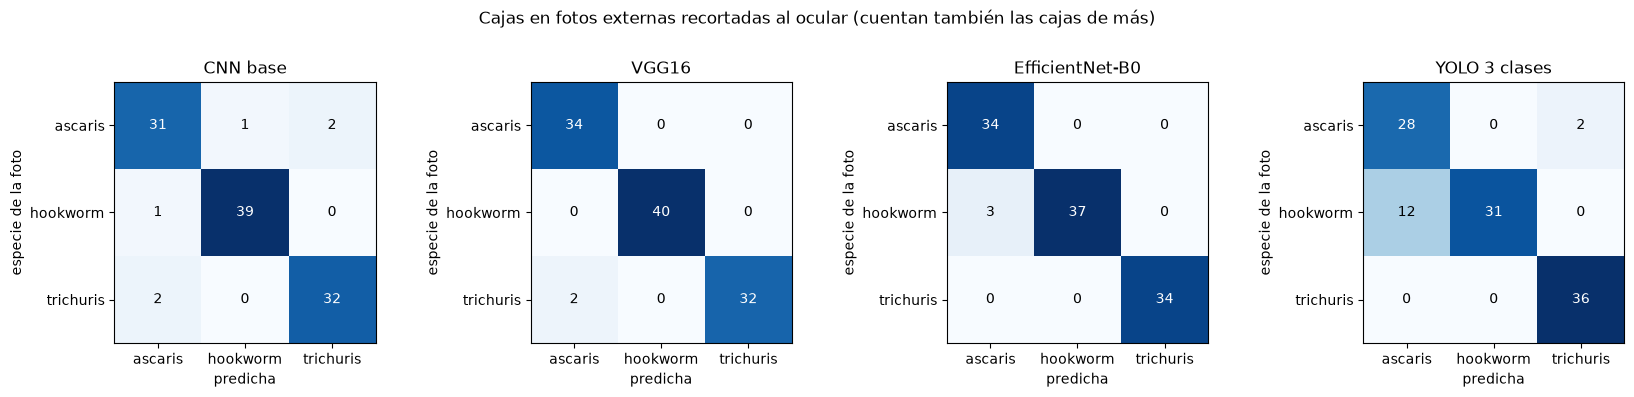

EfficientNet-B0 on cropped external photos: 4 of 108 boxes below 0.65 (sent to review); accuracy of the accepted boxes: 0.981


In [15]:
# Box-level confusion (photo species vs prediction), photos cropped to the ocular.
table, two, one = external['recortadas al ocular']
routes = [(n, two, n) for n in names] + [('YOLO 3 clases', one, 'YOLO 3 clases')]
fig, axes = plt.subplots(1, len(routes), figsize=(4.2 * len(routes), 3.8))
for ax, (label, boxes, column) in zip(axes, routes):
    cm = confusion_matrix(boxes.species, boxes[column], labels=CLASSES)
    ax.imshow(cm, cmap='Blues')
    for i in range(3):
        for j in range(3):
            ax.text(j, i, cm[i, j], ha='center', va='center', color='white' if cm[i, j] > cm.max() * 0.6 else 'black')
    ax.set(title=label, xticks=range(3), yticks=range(3), xticklabels=CLASSES, yticklabels=CLASSES, xlabel='predicha', ylabel='especie de la foto')
plt.suptitle('Cajas en fotos externas recortadas al ocular (cuentan también las cajas de más)', y=1.02)
plt.tight_layout()
plt.show()

conf_col = f'conf {CHOSEN}'
flagged = two[two[conf_col] < REVIEW_BELOW]
print(f'{CHOSEN} on cropped external photos: {len(flagged)} of {len(two)} boxes below {REVIEW_BELOW} (sent to review); '
      f'accuracy of the accepted boxes: {(two[two[conf_col] >= REVIEW_BELOW][CHOSEN] == two[two[conf_col] >= REVIEW_BELOW].species).mean():.3f}')

## 9. Tabla de decisión

Un criterio por fila. La columna "mejor" marca qué red gana, o "empate" si otra queda a menos de 1 % del mejor valor. Cuando la diferencia con la mejor no es significativa en `valid` (sección 3), la exactitud cuenta como empate, y la decisión la toma el costo.

In [16]:
best_f1 = max(summary['F1 valid conjunto 3 semillas'])
decision = pd.DataFrame({
    'F1 valid, conjunto 3 semillas (↑)': summary['F1 valid conjunto 3 semillas'],
    'parámetros, M (↓)': summary['parámetros (M)'],
    'pesos de las 3 semillas, MB (↓)': cost['pesos de las 3 semillas (MB)'],
    'ms por recorte, 3 semillas, CPU (↓)': cost['ms por recorte (3 semillas)'],
    's por foto, YOLO + 3 semillas, CPU (↓)': cost['s por foto, YOLO + 3 semillas'],
    'exactitud de lo aceptado con ≥ 0,65 (↑)': confidence['exactitud de lo aceptado'],
    'ECE, calibración (↓)': confidence['ECE'],
    'F1 con brillo ×1,6 (↑)': pd.Series({n: robust[(n, 'brillo')][-1] for n in names}),
    'F1 con desenfoque radio 2 (↑)': pd.Series({n: robust[(n, 'desenfoque')][2] for n in names}),
    'externas completas, especie % (↑, solo confirma)': pd.Series({n: ext_summary.loc[('completas', f'YOLO 1 clase + {n}'), 'especie correcta (%)'] for n in names}),
    'externas recortadas, especie % (↑, solo confirma)': pd.Series({n: ext_summary.loc[('recortadas al ocular', f'YOLO 1 clase + {n}'), 'especie correcta (%)'] for n in names}),
}).T.astype(float)
TIE = 0.01   # within 1 % (relative) of the best value counts as a tie


def winners(idx, row):
    lower = '(↓)' in idx
    best = row.min() if lower else row.max()
    close = [n for n in names if abs(row[n] - best) <= TIE * abs(best)]
    return close[0] if len(close) == 1 else 'empate: ' + ', '.join(close)


decision['mejor'] = [winners(idx, row) for idx, row in decision[names].iterrows()]
best_name = summary['F1 valid conjunto 3 semillas'].astype(float).idxmax()
tied = [n for n in names if n == best_name or pairs.filter(like=n, axis=0).filter(like=best_name, axis=0)['McNemar p'].min() > 0.05]
print(f'best valid F1: {best_name}; statistically tied with it on valid (McNemar p > 0.05): {tied}')
decision.round(4)

best valid F1: VGG16; statistically tied with it on valid (McNemar p > 0.05): ['CNN base', 'VGG16', 'EfficientNet-B0']


,CNN base,VGG16,EfficientNet-B0,mejor
"F1 valid, conjunto 3 semillas (↑)",0.9927,0.9976,0.9951,"empate: CNN base, VGG16, EfficientNet-B0"
"parámetros, M (↓)",4.7200,14.7200,4.0100,EfficientNet-B0
"pesos de las 3 semillas, MB (↓)",56.6900,176.6200,48.9700,EfficientNet-B0
"ms por recorte, 3 semillas, CPU (↓)",35.3400,112.7200,33.7200,EfficientNet-B0
"s por foto, YOLO + 3 semillas, CPU (↓)",0.1000,0.1800,0.1000,"empate: CNN base, EfficientNet-B0"
"exactitud de lo aceptado con ≥ 0,65 (↑)",1.0000,0.9975,0.9975,"empate: CNN base, VGG16, EfficientNet-B0"
"ECE, calibración (↓)",0.0923,0.0923,0.0783,EfficientNet-B0
"F1 con brillo ×1,6 (↑)",0.9491,0.9613,0.9613,"empate: VGG16, EfficientNet-B0"
F1 con desenfoque radio 2 (↑),0.9634,0.9099,0.9243,CNN base
"externas completas, especie % (↑, solo confirma)",91.4000,96.8000,98.9000,EfficientNet-B0


**Conclusión de la comparación**

1. **Costo: EfficientNet-B0 es la más liviana.** Tiene 4,0 M de parámetros, y los pesos de sus 3 semillas ocupan 49 MB, frente a 57 MB de la CNN y 177 MB de VGG16. En CPU es tan rápida como la CNN: unos 35 ms por recorte con 3 semillas, frente a unos 115 ms de VGG16, y unos 0,10 s por foto con YOLO, frente a 0,17 s.
2. **Confianza: EfficientNet-B0 es la mejor calibrada** (ECE de 0,078 frente a 0,092). Con el umbral de 65 % acepta sin revisión el 98,6 % de los huevos, con 99,75 % de exactitud; las otras dos aceptan cerca del 97 %. Para la app, eso significa menos huevos enviados a revisión con la misma exactitud.
3. **Robustez.** Con brillo extremo (×1,6), EfficientNet-B0 y VGG16 empatan (0,961) por encima de la CNN (0,949). Con desenfoque, en cambio, la CNN aguanta más: con radio 2 da 0,963, frente a 0,924 de EfficientNet-B0 y 0,910 de VGG16. Es el punto débil de las redes preentrenadas, y obliga a pedir fotos bien enfocadas.
4. **Grad-CAM** (observación a ojo, sobre 7 recortes). EfficientNet-B0 concentra el mapa sobre el cuerpo del huevo en la mayoría de los casos; la CNN marca más seguido bordes y fondo. En la uncinaria, las tres miran también el fondo, lo que coincide con la prueba de atajos del análisis exploratorio. Falta la revisión de un parasitólogo.
5. **Fotos externas (solo confirman).** Las redes preentrenadas casi no caen: EfficientNet-B0 acierta 98,9 % con fotos completas y 98 % con fotos recortadas al ocular; VGG16, 96,8 % y 99 %; la CNN, 91,4 % y 94 %. YOLO de 3 clases queda muy por debajo: encuentra menos huevos (85 de 101 con fotos completas, 95 con recortadas) y acierta la especie en el 80 % y el 89,5 %, con las uncinarias como peor caso (15 de 24). Esto justifica el sistema en dos etapas, aunque en Chula los dos detectores tengan el mismo mAP50 (0,995).

**Decisión: EfficientNet-B0.**

- **Exactitud:** empata con las otras dos.
- **Costo:** es la más pequeña, tan rápida como la CNN y unas 3 veces más rápida que VGG16.
- **Confianza:** es la mejor calibrada, lo que importa para el aviso del 65 % de la app.
- **Fotos externas:** su resultado confirma la elección.
- **Punto débil:** el desenfoque.

**Límites.**

- `test` se corrió una sola vez (sección 10), con EfficientNet-B0 ya elegida: F1 macro 0,993 (CNN), 0,995 (VGG16) y 0,998 (EfficientNet-B0).
- Las fotos externas vienen de una sola fuente. El número de huevos por foto se asumió en 1, y hay fotos repetidas del mismo huevo.
- El recorte al ocular se decidió después de ver resultados.
- Las latencias son de este nodo, con 8 hilos, y sirven para comparar las redes entre sí.

## 10. Prueba final en `test` (una sola vez)

`test` está congelado: no se usa para elegir. Esta celda solo corre con `FINAL_TEST = True`, una sola vez, con la red ya elegida y con el visto bueno del equipo.

In [17]:
if FINAL_TEST:
    test = crops[crops.split == 'test'].reset_index(drop=True)
    test_imgs = [pad_to_square(Image.open(ROOT / p).convert('RGB')) for p in test.crop_path]
    y_test = np.array([CLASSES.index(label) for label in test.label])
    rows = {}
    for n in names:
        pred = seed_probs(models[n], test_imgs).mean(0).argmax(1)
        rows[n] = {'accuracy': accuracy_score(y_test, pred), 'f1_macro': f1_score(y_test, pred, average='macro'), 'errores': int((pred != y_test).sum())}
    display(pd.DataFrame(rows).T.round(4))

    # The chosen network, in detail (3-seed ensemble, as in the app).
    from sklearn.metrics import classification_report
    pred = seed_probs(models[CHOSEN], test_imgs).mean(0).argmax(1)
    print(f'{CHOSEN} on test ({len(y_test)} crops):')
    display(pd.DataFrame(classification_report(y_test, pred, target_names=CLASSES, output_dict=True)).T.round(4))
    display(pd.DataFrame(confusion_matrix(y_test, pred, labels=range(3)), index=[f'real {c}' for c in CLASSES], columns=[f'pred {c}' for c in CLASSES]))
    boot = [f1_score(y_test[ix], pred[ix], average='macro') for ix in np.random.default_rng(42).integers(0, len(y_test), (2000, len(y_test)))]
    lo, hi = np.percentile(boot, [2.5, 97.5])
    print(f'F1 macro, 95 % bootstrap interval: [{lo:.4f}, {hi:.4f}]')
else:
    print('FINAL_TEST = False: test stays frozen and is not loaded')

,accuracy,f1_macro,errores
CNN base,0.9927,0.9927,3.0
VGG16,0.9951,0.9951,2.0
EfficientNet-B0,0.9976,0.9976,1.0


EfficientNet-B0 on test (412 crops):


,precision,recall,f1-score,support
ascaris,1.0000,0.9928,0.9964,138.0000
hookworm,1.0000,1.0000,1.0000,138.0000
trichuris,0.9927,1.0000,0.9963,136.0000
accuracy,0.9976,0.9976,0.9976,0.9976
macro avg,0.9976,0.9976,0.9976,412.0000
weighted avg,0.9976,0.9976,0.9976,412.0000


,pred ascaris,pred hookworm,pred trichuris
real ascaris,137,0,1
real hookworm,0,138,0
real trichuris,0,0,136


F1 macro, 95 % bootstrap interval: [0.9924, 1.0000]
